# Roc Tutorial

Welcome to Roc, a A fast, friendly, functional language! This notebook is an executable adaptation of the [Roc tutorial](https://github.com/roc-lang/roc/blob/main/docs/mini-tutorial-new-compiler.md).

## Setup Roc on Colab

1. In a fresh Colab runtime, run the cell below to install Roc, then **refresh the page**.
2. Roc is now active. Skip setup and run the Roc cells in order.

Repeat setup only after Colab resets the runtime. In local Jupyter with iRoc installed, select the **Roc** kernel and delete this setup section.


In [ ]:
!curl -fSL https://raw.githubusercontent.com/ageron/iRoc/main/scripts/setup_colab.py -o /content/setup_iroc.py
%run /content/setup_iroc.py

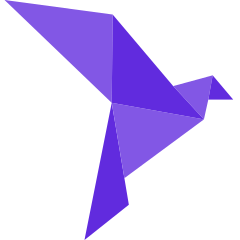

In [ ]:
Svg(
  \\<svg width="240" height="240" viewBox="0 0 51 53" fill="none" xmlns="http://www.w3.org/2000/svg">
  \\  <path d="M23.6751 22.7086L17.655 53L27.4527 45.2132L26.4673 39.3424L23.6751 22.7086Z" fill="#612BDE"/>
  \\  <path d="M37.2438 19.0101L44.0315 26.3689L45 22L45.9665 16.6324L37.2438 19.0101Z" fill="#8257E5"/>
  \\  <path d="M23.8834 3.21052L0 0L23.6751 22.7086L23.8834 3.21052Z" fill="#8257E5"/>
  \\  <path d="M44.0315 26.3689L23.6751 22.7086L26.4673 39.3424L44.0315 26.3689Z" fill="#8257E5"/>
  \\  <path d="M50.5 22L45.9665 16.6324L45 22H50.5Z" fill="#612BDE"/>
  \\  <path d="M23.6751 22.7086L44.0315 26.3689L37.2438 19.0101L23.8834 3.21052L23.6751 22.7086Z" fill="#612BDE"/>
  \\</svg>
)

## Expressions and definitions

Ok, let's start!

An expression produces a value. Define a name with `=` to reuse a value in later cells.

In [3]:
1 + 1

2.0

In [4]:
x = 1 + 1
x * 2

4.0

## Functions, constants, and strings

Functions are values too. `|argument| expression` defines a function; use commas for multiple arguments. A block in braces lets its body contain several statements.

Pure functions return a value without platform effects. Effectful functions conventionally end in `!` and get their I/O operations from a platform. The examples here use pure functions; `dbg` is a debugging facility available inside them.

In [5]:
greet = |person| "Hello, ${person}!"
greet("Rocco")

"Hello, Rocco!"

### Constants
A constant uses a lowercase name and `=`. Within ordinary Roc code, avoid redefining or shadowing constants. The REPL allows replacing a top-level definition when experimenting; that does not make a constant mutable inside a function.

In [6]:
name = "Rocco"
name

"Rocco"

### String interpolation
`${expression}` inserts a string into another string. Convert numbers explicitly with `.to_str()`; interpolation does not automatically convert them.

In [7]:
"Hello, ${name}!"

"Hello, Rocco!"

In [8]:
thing_count = 3.I64
"Number of things: ${thing_count.to_str()}"

"Number of things: 3"

In [9]:
numerator = 8.Dec
denominator = 2.Dec
"Answer: ${((numerator / denominator) + 1).negate().to_str()}"

"Answer: -5.0"

## `for`, `fold`, and tests

Let's convert a list of digits into the number it represents. Roc supports both loops with local mutable variables and a functional style with immutable values.

### The `for` version
`var` introduces a reassignable variable, whose name starts with `$`. A variable can only be reassigned in the function where it was declared: a nested function cannot mutate it. A `for` loop stays in the same function.

In [10]:
digits_to_num = |digits| {
    var $num = 0
    for digit in digits {
        $num = ($num * 10) + digit
    }
    $num
}
digits_to_num([1, 2, 3])

123.0

### `expect`
`expect` checks a Boolean condition. These REPL checks run when the cell executes. Successful checks produce no result of their own, so the last line below displays a confirmation. In a source file, top-level expectations are run by `roc test`.

In [11]:
expect digits_to_num([1, 2, 3]) == 123
expect digits_to_num([4, 2]) == 42
expect digits_to_num([7]) == 7
"All three checks passed."

"All three checks passed."

### The `fold` version
`fold` starts with an accumulator (here `0`) and calls a combining function for each element. This version has the same result without a mutable variable. We give it a separate name so both versions remain available.

In [12]:
digits_to_num_fold = |digits| digits.fold(0, |num, digit| (num * 10) + digit)
expect digits_to_num_fold([1, 2, 3]) == digits_to_num([1, 2, 3])
[digits_to_num_fold([1, 2, 3]), digits_to_num_fold([4, 2]), digits_to_num_fold([7])]

[123.0, 42.0, 7.0]

### Blocks
A block is an expression: its value is the final expression inside the braces. Declarations and loops before it are statements. A function whose body is a block returns that block's final value.

Here `dbg` shows an intermediate value, while the final expression displays the block's result.

In [13]:
{
    foo = 43
    inner_constant = foo - 1
    dbg inner_constant
    inner_constant.abs()
}

42.0


42.0

### Statements versus expressions
Expressions can be passed to functions; statements cannot. For example, a `for` loop alone is not a value, but a block containing a loop and ending in a value is.

In [14]:
{
    var $total = 0
    for number in 1..=10 {
        $total = $total + number
    }
    $total
}

55.0

### Early `return`
`return` exits the enclosing function immediately. Here is the tutorial's early-return example with its remaining implementation filled in.

In [15]:
digits_or_zero = |digits| {
    if digits.is_empty() {
        return 0
    }
    digits.fold(0, |num, digit| (num * 10) + digit)
}
[digits_or_zero([]), digits_or_zero([4, 2])]

[0.0, 42.0]

### `crash`
`crash` stops evaluation when execution cannot meaningfully continue. It is not a replacement for recoverable error handling; use a type such as `Try` for expected failures.

The function below has a crash branch, but we call it with valid input. Calling `nonempty_digits([])` would deliberately fail the cell and stop Run All.

In [16]:
nonempty_digits = |digits| {
    if digits.is_empty() {
        crash "Expected a nonempty list."
    }
    digits.fold(0, |num, digit| (num * 10) + digit)
}
nonempty_digits([4, 2])

42.0

### Expectations inside functions
An `expect` can document an assumption while developing. It is not input validation: optimized applications can omit these checks. Handle recoverable failures explicitly in your function's result.

In [17]:
checked_digits = |digits| {
    if digits.is_empty() {
        return 0
    }
    expect !digits.is_empty()
    digits.fold(0, |num, digit| (num * 10) + digit)
}
[checked_digits([]), checked_digits([1, 2, 3])]

[0.0, 123.0]

### Debugging with `dbg`
`dbg` can inspect a value even inside a pure function. iRoc displays captured debug output alongside the cell's final result. It is debugging output, not a platform printing API; in other environments its destination and evaluation timing can differ.

In [18]:
double_with_debug = |value| {
    dbg value
    value * 2
}
double_with_debug(5)

5.0


10.0

## Conditionals and collections

### `if` expressions
An `if` expression chooses a value. Both branches must have compatible types. Short branches can go on one line; braces are useful for longer branches.

In [19]:
str : Str
str = ""
display_name = if str.is_empty() "n/a" else str
display_name

"n/a"

In [20]:
name_or_default = |text| {
    if text.is_empty() {
        "n/a"
    } else {
        text
    }
}
[name_or_default(""), name_or_default("Rocco")]

["n/a", "Rocco"]

### Records
Records group named fields. Field values can have different types. `Bool.True` and `Bool.False` are qualified spellings of the Boolean values.

In [21]:
record = if str.is_empty() {
    { name: "n/a", has_name: Bool.False }
} else {
    { name: str, has_name: Bool.True }
}
record

{ has_name: False, name: "n/a" }

A record update creates a new value; the original record stays unchanged.

In [22]:
new_record = { ..record, name: "New Name" }
{ original: record, updated: new_record }

{ original: { has_name: False, name: "n/a" }, updated: { has_name: False, name: "New Name" } }

Destructure a record to name its fields. Use `name: record_name` to bind a field under a different local name and avoid shadowing the earlier `name` constant.

In [23]:
{
    { name: record_name, has_name } = record
    (record_name, has_name)
}

("n/a", False)

### Lists and method calls
All elements of a list must have compatible types. `List.len(animals)` and `animals.len()` are two ways to call the same function: method syntax uses the type of the receiver to find the function.

In [24]:
animals = ["bird", "crab", "lizard"]
animals

["bird", "crab", "lizard"]

In [25]:
{ function_call: List.len(animals), method_call: animals.len(), first: animals.first() }

{ first: Ok("bird"), function_call: 3, method_call: 3 }

### Pattern matching
`match` selects the first matching branch. List patterns can match exact contents, bind elements, or allow extra elements with `..`. `_` covers the remaining cases.

The tutorial references `count_points`; here we supply a simple implementation and try several branches.

In [26]:
count_points = |first, second| first.count_utf8_bytes() + second.count_utf8_bytes()
points_for = |items| match items {
    ["bird", "crab", "lizard"] => 10
    ["bird", "crab", ..] => 5
    ["bird", ..] => 1
    [first, second, "lizard", ..] => count_points(first, second)
    _ => 0
}
[points_for(animals), points_for(["bird", "crab"]), points_for(["bird"]), points_for(["cat", "dog", "lizard"]), points_for([])]

[10, 5, 1, 6, 0]

### Tags
A list such as `["eagle", 1]` is invalid because strings and numbers do not have compatible types. Tags let us represent alternatives within one type: a value can be `Bird` with a string or `Number` with a number.

In [27]:
birds_or_numbers = [Bird("eagle"), Number(1)]
birds_or_numbers

[Bird("eagle"), Number(1.0)]

Pattern matching unwraps the tag's payload. Tags can also have no payload, as the error tags in the next examples demonstrate.

In [28]:
label = match birds_or_numbers {
    [Bird(bird), Number(num)] => "${bird} number ${num.to_str()}"
    _ => ""
}
label

"eagle number 1.0"

## Success and failure with `Try`
Roc uses `Ok(value)` and `Err(problem)` to represent success and failure instead of `null`. For example, `List.first` returns `Err(ListWasEmpty)` on an empty list. An error is a normal value that you can inspect and handle.

In [29]:
numbers = [1.I64, 2, 3]
number = match numbers.first() {
    Ok(first) => first + 1
    Err(ListWasEmpty) => 0
}
number

2

In [30]:
empty_numbers : List(I64)
empty_numbers = []
{ nonempty: numbers.first(), empty: empty_numbers.first(), invalid_number: I64.from_str("not a number") }

{ empty: Err(ListWasEmpty), invalid_number: Err(BadNumStr), nonempty: Ok(1) }

### Combining error cases
The next function can produce either `ListWasEmpty` or `BadNumStr` as its error. Matching those cases explicitly documents how each should be handled. The parser branch below is selected for an empty list, as in the original tutorial.

In [31]:
first_or_parse = |items, text| {
    num_or_err = if items.is_empty() {
        I64.from_str(text)
    } else {
        items.first()
    }
    match num_or_err {
        Ok(num) => num + 1
        Err(ListWasEmpty) => 0
        Err(BadNumStr) => -1
    }
}
[first_or_parse(numbers, "1"), first_or_parse(empty_numbers, "1"), first_or_parse(empty_numbers, "oops")]

[2, 2, -1]

### Exhaustiveness
A match must handle every possible case. The previous match needs no `_` branch because all success and error variants are listed. Explicit cases help the compiler point out errors you forgot to handle when a type changes; an unnecessary catch-all can also be reported as redundant.

### Numeric types
`I64` is a signed 64-bit integer; `U64` is unsigned. Roc also has other integer widths, binary floating-point types `F32` and `F64`, and fixed-point `Dec`. Unconstrained number literals default to `Dec`, so this decimal comparison is exact.

In [32]:
0.1 + 0.2 == 0.3

True

### `Try` methods and underscore patterns
`ok_or` extracts a successful value or supplies a default on error. The same operation can be written with a match. `Err(_)` ignores the error payload, so it works with different error types.

In [33]:
[numbers.first().ok_or(0), empty_numbers.first().ok_or(0)]

[1, 0]

In [34]:
ok_or = |attempt, default_value| match attempt {
    Ok(val) => val
    Err(_) => default_value
}
[ok_or(numbers.first(), 0), ok_or(I64.from_str("oops"), -1)]

[1, -1]

### Propagating errors with `?`
The postfix `?` unwraps an `Ok`, or returns the `Err` immediately from the enclosing function. This keeps a sequence of fallible operations concise. All three calls below complete normally: even the failures are returned as values, not notebook errors.

In [35]:
increment_first = |strings| {
    first_str = strings.first()?
    first_num = I64.from_str(first_str)?
    Ok(first_num + 1)
}
[increment_first(["41"]), increment_first([]), increment_first(["oops"])]

[Ok(42), Err(ListWasEmpty), Err(BadNumStr)]

Here is the same function with explicit matches and early returns. The checks compare its behavior with the shorter version.

In [36]:
increment_first_explicit = |strings| {
    first_str = match strings.first() {
        Ok(val) => val
        Err(err) => return Err(err)
    }
    first_num = match I64.from_str(first_str) {
        Ok(val) => val
        Err(err) => return Err(err)
    }
    Ok(first_num + 1)
}
expect increment_first_explicit(["41"]) == increment_first(["41"])
expect increment_first_explicit([]) == increment_first([])
expect increment_first_explicit(["oops"]) == increment_first(["oops"])
"Both versions agree."

"Both versions agree."

## Types
Roc checks types statically even when you omit annotations. Type inference does not mean values are dynamically typed: adding a string to a number still produces a diagnostic. Values are semantically immutable; a local `var` allows rebinding within a function.

### Type annotations
An annotation goes above a definition. Use distinct names to avoid shadowing definitions from earlier cells.

In [37]:
{
    annotated_name : Str
    annotated_name = "Sam"
    is_empty : Bool
    is_empty = annotated_name.is_empty()
    { name: annotated_name, is_empty }
}

{ is_empty: False, name: "Sam" }

### Parameterized types
`List(Str)` means a list of strings; `List(I64)` means a list of signed 64-bit integers. `Try(success, error)` has two parameters, one for each outcome.

In [38]:
strings : List(Str)
strings = ["a", "b", "c"]
integers : List(I64)
integers = [1, 2, 3]
{ strings, integers }

{ integers: [1, 2, 3], strings: ["a", "b", "c"] }

### Function types
Pure function types use `->`; multiple arguments are separated by commas. Effectful function types use `=>`. The tutorial's file-reading function needs a platform and is intentionally not included as executable REPL code.

Division below is decimal division because the arguments are annotated `Dec`. The literal `2` does not need to be written as `2.0`.

In [39]:
average : Dec, Dec -> Dec
average = |a, b| (a + b) / 2
average(3, 4)

3.5

The REPL's `:t` command shows a definition's checked type without evaluating it.

In [40]:
:t average

average : Dec, Dec -> Dec

### Type variables
A lowercase type variable stands for a type chosen by the caller. This function accepts and returns a list with the same element type, and works for both our string and integer lists.

In [41]:
type_var : List(a) -> List(a)
type_var = |lst| lst
{ words: type_var(strings), values: type_var(integers) }

{ values: [1, 2, 3], words: ["a", "b", "c"] }

A `where` clause requires a method on the chosen type. `stringify` accepts any type with a compatible `to_str` method.

In [42]:
stringify : a -> Str where [a.to_str : a -> Str]
stringify = |value| value.to_str()
[stringify(42.I64), stringify(3.5.Dec)]

["42", "3.5"]

### Structural types and tag unions
A structural type describes a shape. A tag union lists the alternatives a value may take. Error unions let several operations describe their possible failures precisely.

Here the annotation makes the success and error types of a digit conversion explicit. Unlike the earlier crash example, empty input is a recoverable error value.

In [43]:
parse_digits : List(I64) -> Try(I64, [EmptyDigits])
parse_digits = |digits| {
    if digits.is_empty() {
        Err(EmptyDigits)
    } else {
        Ok(digits.fold(0, |num, digit| (num * 10) + digit))
    }
}
[parse_digits([4, 2]), parse_digits([])]

[Ok(42), Err(EmptyDigits)]

### Nominal types
`:=` creates a distinct named type, rather than just another name for a shape. The tutorial's `Color` enumeration has three variants with no payload. Qualified variants identify their nominal type.

In [44]:
Color := [Red, Green, Blue]
color_name = |color| match color {
    Color.Red => "red"
    Color.Green => "green"
    Color.Blue => "blue"
}
[color_name(Color.Red), color_name(Color.Green), color_name(Color.Blue)]

["red", "green", "blue"]

## Beyond the notebook

An application chooses a platform to supply its I/O capabilities. The standard library supplies pure operations; platforms provide effects such as file access, networking, or graphics. Application headers, platform dependencies, and entrypoints belong in `.roc` files rather than these REPL cells. See the [original tutorial's dependencies section](https://github.com/roc-lang/roc/blob/main/docs/mini-tutorial-new-compiler.md#dependencies) when moving to a standalone application.

Useful next steps:

- [Standard library and language documentation](https://roc-lang.org/docs/main/)
- [Roc examples](https://roc-lang.org/examples/)
- [Current syntax overview](https://github.com/roc-lang/roc/blob/main/test/echo/all_syntax_test.roc)
- [Learn by doing with Exercism](https://exercism.org/tracks/roc/)
- [Ask questions on Roc Zulip](https://roc.zulipchat.com/)

Try extending `parse_digits` to return an `InvalidDigit` error when an element lies outside `0..=9`. Then add expectations for a valid list, an empty list, and a list containing `12`.